# **TP2 : Préparation et qualité des sources**

***COMMENT ALLEZ-VOUS RAISONNER ?*****

> **> 1-Quelles anomalies devez-vous mesurer avant de modifier les données ?**

Il faut mesurer les valeurs manquantes par colonne, les doublons strictement identiques sur les huit colonnes métier, les factures dont le numéro commence par C, les quantités inférieures ou égales à zéro, les prix unitaires inférieurs ou égaux à zéro, les CustomerID manquants et les codes produits potentiellement non commerciaux.

> **> 2-Pourquoi InvoiceNo commençant par C ne doit-il pas être supprimé sans trace ?**

Les supprimer sans trace ferait perdre une information métier et empêcherait de justifier les écarts entre la source brute et la source préparée.

> **> 3-Pourquoi InvoiceNo + StockCode ne constitue-t-il pas une clé de ligne ?**

Une même facture peut contenir plusieurs lignes portant le même code produit, par exemple lorsque les lignes ont des caractéristiques ou des valeurs différentes. Dédupliquer avec seulement InvoiceNo et StockCode pourrait donc supprimer des lignes légitimes

> **> 4-Que faire d'un CustomerID manquant ?**

Conserver la ligne et son information de vente pour un rattachement ultérieur à « Client inconnu ». L'absence de CustomerID ne suffit pas à supprimer une vente.

> **> 5-Comment distinguer un code non commercial d'un code commercial alphanumérique ?**

La présence d'une lettre dans StockCode ne suffit pas pour exclure une ligne. La classification doit s'appuyer sur StockCode, Description et le comportement de la référence, selon la table de classification validée fournie avec le dossier. En l'absence de cette référence, les cas ambigus doivent être marqués A_VERIFIER, et non classés arbitrairement.

> **> 6-Quels contrôles prouvent l'effet des transformations ?**

Comparer avant/après le nombre de lignes, les doublons exacts, les CustomerID manquants, les annulations/retours, les lignes avec Quantity <= 0, les lignes avec UnitPrice <= 0, les lignes non commerciales et la somme de MontantLigne.

**7------CODE / MANIPULATION****

In [5]:
import pandas as pd
df = pd.read_excel("/kaggle/input/datasets/nisrineqacem/online-retail/Online Retail.xlsx")
print("Dimensions :", df.shape)
print(df.dtypes)
print("\nValeurs manquantes :")
print(df.isna().sum())
print("\nDoublons exacts :", df.duplicated().sum())
print("\nQuantity :")
print(df["Quantity"].describe())
print("\nUnitPrice :")
print(df["UnitPrice"].describe())
print("\nInvoiceNo commençant par C :")
print(df["InvoiceNo"].astype(str).str.startswith("C").sum())

Dimensions : (541909, 8)
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Valeurs manquantes :
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Doublons exacts : 5268

Quantity :
count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

UnitPrice :
count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

InvoiceNo commençant par C :


> ***QUE CONSTATEZ-VOUS ?***

Les résultats du profilage permettent d'identifier les dimensions du dataset, les types de données, les valeurs manquantes, les doublons exacts, les quantités, les prix et les factures d'annulation commençant par C. Les valeurs exactes doivent être relevées après l'exécution du code.

> ***QUEL TRAITEMENT DÉCIDEZ-VOUS D’APPLIQUER ?***
- Doublons : supprimer uniquement les lignes identiques sur les huit colonnes.
- Valeurs manquantes : conserver les ventes dont CustomerID est manquant.
- Factures commençant par C : les exclure du MVP des ventes, mais les conserver dans l'audit.
- Quantités et prix : exclure du MVP les lignes avec Quantity <= 0 ou UnitPrice <= 0.
- Lignes non commerciales : appliquer la classification de référence du dataset ; les cas incertains restent A_VERIFIER.

**8------MISSION TECHNIQUE**

,Phénomène,Nombre de lignes
0,Factures commençant par C,9288
1,Quantity <= 0,10624
2,UnitPrice <= 0,2517
3,CustomerID manquant,135080
4,Doublons exacts,5268
5,Description manquante,1454
6,StockCode manquant,0


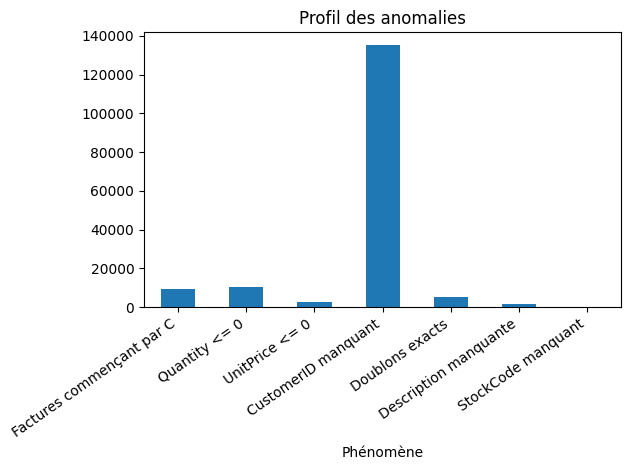

In [8]:
## 4. Mesurer les anomalies
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("/kaggle/input/datasets/nisrineqacem/online-retail/Online Retail.xlsx")

anomalies = pd.DataFrame({
    "Phénomène": [
        "Factures commençant par C",
        "Quantity <= 0",
        "UnitPrice <= 0",
        "CustomerID manquant",
        "Doublons exacts",
        "Description manquante",
        "StockCode manquant"
    ],
    "Nombre de lignes": [
        df["InvoiceNo"].astype(str).str.startswith("C").sum(),
        (df["Quantity"] <= 0).sum(),
        (df["UnitPrice"] <= 0).sum(),
        df["CustomerID"].isna().sum(),
        df.duplicated().sum(),
        df["Description"].isna().sum(),
        df["StockCode"].isna().sum()
    ]
})

display(anomalies)

anomalies.plot(x="Phénomène", y="Nombre de lignes", kind="bar",
               legend=False, title="Profil des anomalies")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Analyser les anomalies 

> **— Une quantité négative est-elle nécessairement une erreur ? Quelle règle du MVP s'applique ?**

Une quantité négative n’est pas nécessairement une erreur : elle peut correspondre à un retour de marchandise.
Règle du MVP : seules les lignes avec Quantity > 0, UnitPrice > 0, une facture non annulée et TypeLigne = PRODUIT_COMMERCIAL sont incluses dans FactVente. Les retours sont exclus du MVP, mais conservés dans l’audit pour assurer la traçabilité.

### Normaliser sans inventer 

> **Pourquoi faut-il conserver les valeurs originales lors d’une normalisation ?**

Il faut conserver les valeurs originales pour assurer la traçabilité et pouvoir comparer les données avant et après la normalisation.

In [9]:
# Garder les valeurs originales
df["Description_Original"] = df["Description"]
df["Country_Original"] = df["Country"]
df["StockCode_Original"] = df["StockCode"]

# Supprimer les espaces inutiles
df["Description"] = df["Description"].str.strip()
df["Country"] = df["Country"].str.strip()
df["StockCode"] = df["StockCode"].str.strip()

display(df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Description_Original,Country_Original,StockCode_Original
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom,85123A
1,536365,NaN,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,WHITE METAL LANTERN,United Kingdom,71053
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,CREAM CUPID HEARTS COAT HANGER,United Kingdom,84406B
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,KNITTED UNION FLAG HOT WATER BOTTLE,United Kingdom,84029G
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,RED WOOLLY HOTTIE WHITE HEART.,United Kingdom,84029E


### Dédoublonner exactement

> **— Pourquoi deux lignes ayant le même InvoiceNo et StockCode peuvent-elles être légitimes ?**

Deux lignes peuvent avoir la même facture et le même produit, mais des quantités ou des prix différents. On supprime uniquement les lignes identiques sur les huit colonnes sources.

In [10]:
colonnes = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]

print("Doublons avant :", df.duplicated(subset=colonnes).sum())

df = df.drop_duplicates(subset=colonnes)

print("Dimensions après :", df.shape)
print("Doublons après :", df.duplicated(subset=colonnes).sum())

Doublons avant : 5269
Dimensions après : (536640, 11)
Doublons après : 0


### Classifier les lignes 

> **Pourquoi la présence d’une lettre dans StockCode ne suffit-elle pas à exclure une ligne** ?

La présence d’une lettre ne signifie pas nécessairement que le code est non commercial. La classification doit s’appuyer sur StockCode, Description et le comportement de la ligne.

In [11]:
def classifier_ligne(row):
    if str(row["InvoiceNo"]).startswith("C"):
        return "ANNULATION"
    elif row["Quantity"] <= 0:
        return "RETOUR_OU_QUANTITE_NULLE"
    elif row["UnitPrice"] <= 0:
        return "PRIX_NUL_OU_NEGATIF"
    elif pd.isna(row["Description"]) or pd.isna(row["StockCode"]):
        return "A_VERIFIER"
    else:
        return "PRODUIT_COMMERCIAL"

df["TypeLigne"] = df.apply(classifier_ligne, axis=1)

display(df[["InvoiceNo", "StockCode", "Description",
            "Quantity", "UnitPrice", "TypeLigne"]].head(10))

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,TypeLigne
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,PRODUIT_COMMERCIAL
1,536365,NaN,WHITE METAL LANTERN,6,3.39,A_VERIFIER
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75,PRODUIT_COMMERCIAL
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,PRODUIT_COMMERCIAL
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,PRODUIT_COMMERCIAL
5,536365,NaN,SET 7 BABUSHKA NESTING BOXES,2,7.65,A_VERIFIER
6,536365,NaN,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,A_VERIFIER
7,536366,NaN,HAND WARMER UNION JACK,6,1.85,A_VERIFIER
8,536366,NaN,HAND WARMER RED POLKA DOT,6,1.85,A_VERIFIER
9,536367,NaN,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,A_VERIFIER


### Construire la source préparée 

> **Quelle différence entre « exclue de FactVente » et « supprimée de la source » ?**

La source préparée conserve uniquement les lignes qui respectent les règles du MVP. Les lignes exclues restent conservées séparément pour l’audit afin d’assurer la traçabilité.

In [12]:
# Filtrer les lignes selon les règles du MVP
mask = (
    ~df["InvoiceNo"].astype(str).str.startswith("C")
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
    & (df["TypeLigne"] == "PRODUIT_COMMERCIAL")
)

# Conserver les lignes exclues pour l'audit
df_audit = df[~mask].copy()

# Créer la source préparée
df_l2 = df[mask].copy()

print("Lignes préparées :", len(df_l2))
print("Lignes exclues et conservées pour audit :", len(df_audit))

Lignes préparées : 52625
Lignes exclues et conservées pour audit : 484015


### Créer le montant dérivé

> **Pourquoi conserver Quantity et UnitPrice alors que MontantLigne existe ?**

On conserve les deux colonnes pour vérifier le calcul, analyser séparément les quantités et les prix, et assurer la traçabilité.

In [13]:
df_l2["MontantLigne"] = df_l2["Quantity"] * df_l2["UnitPrice"]

display(df_l2[["Quantity", "UnitPrice", "MontantLigne"]].head())
print("Montant total :", df_l2["MontantLigne"].sum())

,Quantity,UnitPrice,MontantLigne
0,6,2.55,15.30
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34
45,3,18.00,54.00


Montant total : 1296613.1339999998


**9-----CONTRÔLES TECHNIQUES****

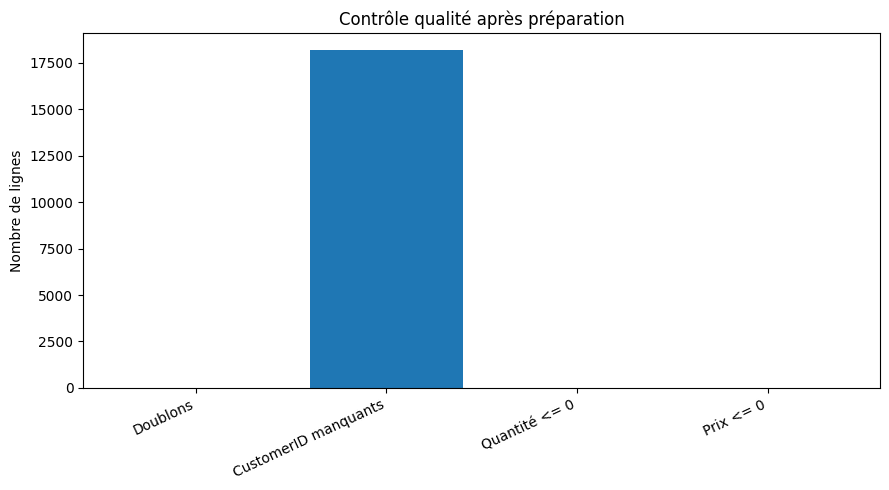

In [15]:
import matplotlib.pyplot as plt

anomalies = {
    "Doublons": df_l2.duplicated().sum(),
    "CustomerID manquants": df_l2["CustomerID"].isna().sum(),
    "Quantité <= 0": (df_l2["Quantity"] <= 0).sum(),
    "Prix <= 0": (df_l2["UnitPrice"] <= 0).sum()
}

plt.figure(figsize=(9, 5))
plt.bar(anomalies.keys(), anomalies.values())
plt.title("Contrôle qualité après préparation")
plt.ylabel("Nombre de lignes")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Le graphique permet de comparer les anomalies restantes après préparation et de vérifier l’effet des règles appliquées. Les valeurs doivent être interprétées en fonction des filtres du MVP.

**10------ANALYSE ET INTERPRÉTATION**

Nombre de lignes : 541909


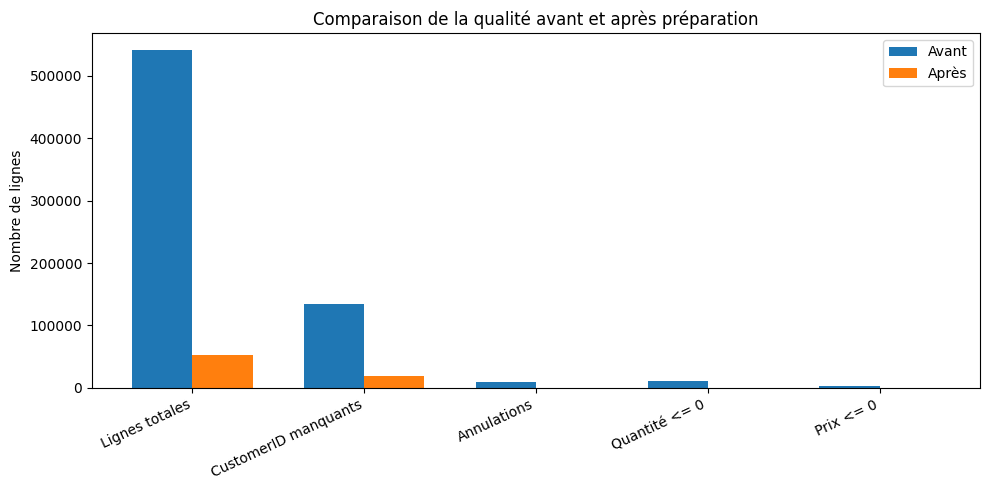

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df_raw = pd.read_excel(
    "/kaggle/input/datasets/nisrineqacem/online-retail/Online Retail.xlsx"
)

print("Nombre de lignes :", len(df_raw))
avant = [
    len(df_raw),
    df_raw["CustomerID"].isna().sum(),
    df_raw["InvoiceNo"].astype(str).str.startswith("C").sum(),
    (df_raw["Quantity"] <= 0).sum(),
    (df_raw["UnitPrice"] <= 0).sum()
]

apres = [
    len(df_l2),
    df_l2["CustomerID"].isna().sum(),
    df_l2["InvoiceNo"].astype(str).str.startswith("C").sum(),
    (df_l2["Quantity"] <= 0).sum(),
    (df_l2["UnitPrice"] <= 0).sum()
]

labels = ["Lignes totales", "CustomerID manquants",
          "Annulations", "Quantité <= 0", "Prix <= 0"]

x = np.arange(len(labels))
largeur = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - largeur/2, avant, largeur, label="Avant")
plt.bar(x + largeur/2, apres, largeur, label="Après")
plt.xticks(x, labels, rotation=25, ha="right")
plt.ylabel("Nombre de lignes")
plt.title("Comparaison de la qualité avant et après préparation")
plt.legend()
plt.tight_layout()
plt.show()

**Observation**
> **— Quels changements sont mesurés ?**

On compare le nombre de lignes, les valeurs manquantes, les annulations, les quantités non positives et les prix non positifs avant et après la préparation.


**Analyse**
> **— Pourquoi ces changements apparaissent-ils ?**

Ils sont dus à la suppression des doublons exacts et à l’application des règles du MVP. Les lignes hors périmètre sont exclues de la source préparée, mais conservées dans l’audit.


**Interprétation** 
> **— Quelles règles métier expliquent les exclusions et les conservations ?**

Les annulations, les quantités non positives, les prix non positifs et les lignes non commerciales sont exclues du MVP. Les CustomerID manquants sont conservés si les autres règles sont respectées.

**11------Défi technique** 

In [19]:
colonnes_attendues = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]

df_dedup = df_raw.drop_duplicates(
    subset=colonnes_attendues,
    keep="first"
).copy()

print("Lignes avant :", len(df_raw))
print("Lignes après :", len(df_dedup))
print("Doublons exacts retirés :", len(df_raw) - len(df_dedup))
# Nombre de lignes avec CustomerID manquant dans la source brute
manquants_avant = df_raw["CustomerID"].isna().sum()

# Nombre de lignes avec CustomerID manquant après dédoublonnage
manquants_apres = df_dedup["CustomerID"].isna().sum()

print("Avant dédoublonnage :", manquants_avant)
print("Après dédoublonnage :", manquants_apres)

if manquants_apres <= manquants_avant:
    print("Contrôle effectué : vérifier les doublons exacts retirés.")

if manquants_apres == df_dedup[df_dedup["CustomerID"].isna()].shape[0]:
    print("Les lignes restantes avec CustomerID manquant sont conservées.")

Lignes avant : 541909
Lignes après : 536641
Doublons exacts retirés : 5268
Avant dédoublonnage : 135080
Après dédoublonnage : 135037
Contrôle effectué : vérifier les doublons exacts retirés.
Les lignes restantes avec CustomerID manquant sont conservées.


Avant préparation : 135037
Après préparation : 132186
ERREUR : des lignes avec CustomerID manquant ont été supprimées.


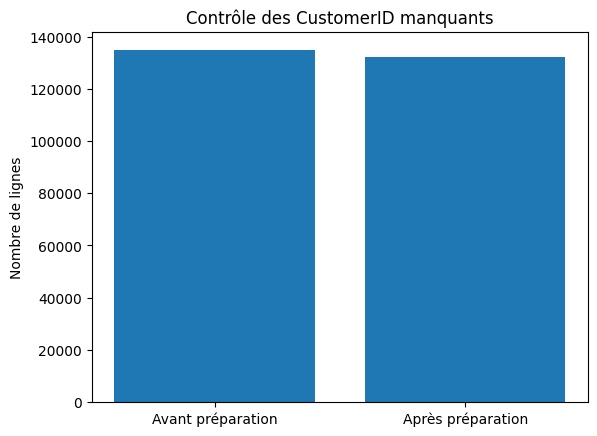

In [25]:
# Défi technique : détecter la suppression des CustomerID manquants

import matplotlib.pyplot as plt

# Compter les CustomerID manquants avant et après
avant = df_dedup["CustomerID"].isna().sum()
apres = df_l2["CustomerID"].isna().sum()

# Afficher les résultats
print("Avant préparation :", avant)
print("Après préparation :", apres)

if apres < avant:
    print("ERREUR : des lignes avec CustomerID manquant ont été supprimées.")
else:
    print("Aucune diminution du nombre de CustomerID manquants détectée.")

# Créer le graphique
plt.bar(["Avant préparation", "Après préparation"], [avant, apres])
plt.title("Contrôle des CustomerID manquants")
plt.ylabel("Nombre de lignes")
plt.show()

**Interprétation du graph**

Le graphique permet de comparer le nombre de lignes avec CustomerID manquant avant et après la préparation. Si le nombre diminue, cela peut indiquer que des lignes ont été supprimées à tort. Selon les règles du TP, les lignes avec CustomerID manquant doivent être conservées. Ce contrôle permet donc de repérer une éventuelle erreur de préparation.